saved the figure
saved the animation


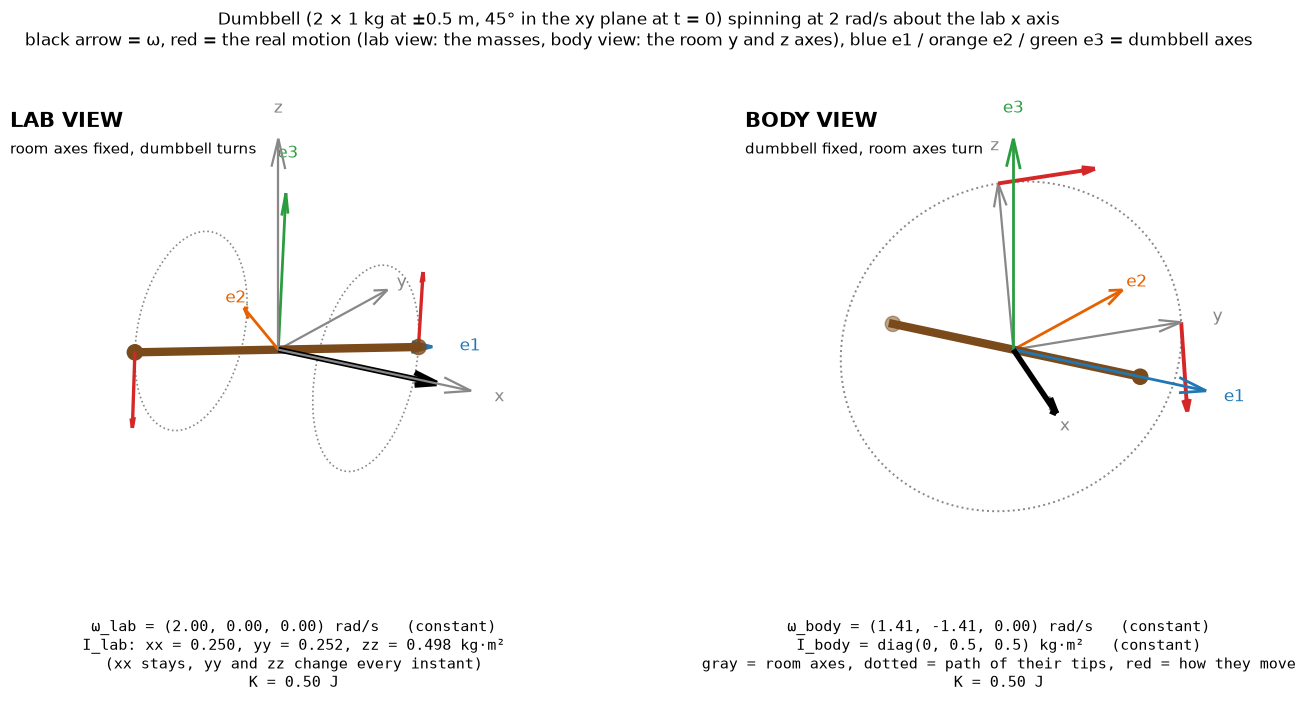

In [4]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from matplotlib.animation import FuncAnimation, PillowWriter  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------
# STEP 1: the dumbbell and the spin
#   What we have: two 1 kg masses at +-0.5 m along e1, e1 at 45 degrees in the xy plane at t = 0
#                 spin omega = 2 rad/s about the LAB x axis
#   What we want: the dumbbell's position at time t in lab axes and in body axes
#   Why: to watch the same spin from the room (lab view) and from the dumbbell (body view)
#   R(t) = Rx(2 t) R0 = [e1 e2 e3] (columns = body axes in lab coordinates), R0 = rotation by 45 deg about z
#   omega_body = R^T omega_lab,   I_lab = R I_body R^T,   v_lab = omega_lab x r_lab
# ---------------------------------------------------------------
MASS, HALF_LEN, OMEGA = 1.0, 0.5, 2.0
OMEGA_LAB = np.array([OMEGA, 0.0, 0.0])
I_BODY = np.diag([0.0, 0.5, 0.5])
A0 = np.deg2rad(45.0)
R0 = np.array([[np.cos(A0), -np.sin(A0), 0.0], [np.sin(A0), np.cos(A0), 0.0], [0.0, 0.0, 1.0]])
N_FRAMES, FPS = 72, 20
GRAY, BLUE, ORANGE, GREEN, BROWN, RED = "#888888", "#1f77b4", "#e66100", "#2a9d3f", "#7a4a1a", "#d62728"


def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


def arrow(ax, v, color, lw, label=None, scale=1.0, lab_off=1.14, origin=(0, 0, 0), shift=(0, 0, 0)):
    v = np.asarray(v, dtype=float)
    ax.quiver(*origin, *(scale * v), color=color, linewidth=lw, arrow_length_ratio=0.14)
    if label:
        ax.text(*(np.asarray(origin) + lab_off * scale * v + np.asarray(shift)), label, color=color,
                fontsize=12, ha="center", va="center")


def setup(ax):
    ax.set_xlim(-0.8, 0.8)
    ax.set_ylim(-0.8, 0.8)
    ax.set_zlim(-0.8, 0.8)
    ax.set_box_aspect((1, 1, 1), zoom=1.5)
    ax.view_init(elev=20, azim=-58)
    ax.set_axis_off()


# ---------------------------------------------------------------
# STEP 2: draw one instant in both views
#   What we have: angle theta = OMEGA t
#   What we want: left panel = room axes fixed, dumbbell turns; right panel = dumbbell fixed, room axes turn
#   Why: same motion, two descriptions; K = 1/2 omega^T I omega is the same number in both
# ---------------------------------------------------------------
def draw(theta, ax_lab, ax_body, txt_lab, txt_body):
    R = Rx(theta) @ R0
    e1, e2, e3 = R[:, 0], R[:, 1], R[:, 2]
    w_body = R.T @ OMEGA_LAB
    I_lab = R @ I_BODY @ R.T
    K_lab = 0.5 * OMEGA_LAB @ I_lab @ OMEGA_LAB
    K_body = 0.5 * w_body @ I_BODY @ w_body
    assert abs(K_lab - K_body) < 1e-12

    # ---- lab view
    ax = ax_lab
    ax.cla()
    setup(ax)
    for v, lab in ((np.array([1.0, 0, 0]), "x"), (np.array([0, 1.0, 0]), "y"), (np.array([0, 0, 1.0]), "z")):
        arrow(ax, v, GRAY, 1.6, lab, scale=0.75)
    phi = np.linspace(0, 2 * np.pi, 120)
    rr = HALF_LEN * np.sin(A0)
    for s in (1, -1):
        ax.plot(np.full_like(phi, s * rr), rr * np.cos(phi), rr * np.sin(phi), color=GRAY, ls=":", lw=1.2)
    p = HALF_LEN * e1
    ax.plot([-p[0], p[0]], [-p[1], p[1]], [-p[2], p[2]], color=BROWN, lw=6, zorder=5)
    ax.scatter([-p[0], p[0]], [-p[1], p[1]], [-p[2], p[2]], s=120, color=BROWN, zorder=6)
    for s in (1, -1):
        r = s * p
        v = np.cross(OMEGA_LAB, r)
        arrow(ax, v, RED, 2.4, None, scale=0.38, origin=r)
    arrow(ax, e1, BLUE, 2.0, "e1", scale=0.55, lab_off=1.25)
    arrow(ax, e2, ORANGE, 2.0, "e2", scale=0.55, lab_off=1.25)
    arrow(ax, e3, GREEN, 2.0, "e3", scale=0.55, lab_off=1.25)
    arrow(ax, OMEGA_LAB / OMEGA, "black", 4.0, None, scale=0.62)
    ax.text2D(0.0, 0.97, "LAB VIEW", transform=ax.transAxes, fontsize=15, fontweight="bold", va="top")
    ax.text2D(0.0, 0.91, "room axes fixed, dumbbell turns", transform=ax.transAxes, fontsize=10.5, va="top")
    txt_lab.set_text(f"ω_lab = (2.00, 0.00, 0.00) rad/s   (constant)\n"
                     f"I_lab: xx = {I_lab[0, 0]:.3f}, yy = {I_lab[1, 1]:.3f}, zz = {I_lab[2, 2]:.3f} kg·m²\n"
                     f"(xx stays, yy and zz change every instant)\n"
                     f"K = {K_lab:.2f} J")

    # ---- body view (dumbbell at rest in its own axes, room axes turn)
    ax = ax_body
    ax.cla()
    setup(ax)
    for v, c, lab in ((np.array([1.0, 0, 0]), BLUE, "e1"), (np.array([0, 1.0, 0]), ORANGE, "e2"),
                      (np.array([0, 0, 1.0]), GREEN, "e3")):
        arrow(ax, v, c, 2.0, lab, scale=0.75)
    pb = np.array([HALF_LEN, 0.0, 0.0])
    ax.plot([-pb[0], pb[0]], [0, 0], [0, 0], color=BROWN, lw=6, zorder=5)
    ax.scatter([-pb[0], pb[0]], [0, 0], [0, 0], s=120, color=BROWN, zorder=6)
    # dotted path traced by the tips of the room y and z axes as seen from the dumbbell (circle around omega)
    path = np.array([0.6 * (R0.T @ Rx(f).T @ np.array([0.0, 1.0, 0.0])) for f in phi])
    ax.plot(path[:, 0], path[:, 1], path[:, 2], color=GRAY, ls=":", lw=1.4)
    for k, lab in enumerate(("x", "y", "z")):
        arrow(ax, R.T[:, k], GRAY, 1.6, lab, scale=0.6, lab_off=1.22)
    # the real motion in the body view: the tips of the room y and z axes go around omega
    # the room turns with -omega_body relative to the dumbbell, so tip velocity = -omega_body x tip
    for k in (1, 2):
        tip = 0.6 * R.T[:, k]
        arrow(ax, -np.cross(w_body, tip), RED, 2.8, None, scale=0.28, origin=tip)
    arrow(ax, w_body / OMEGA, "black", 4.0, None, scale=0.62)
    ax.text2D(0.0, 0.97, "BODY VIEW", transform=ax.transAxes, fontsize=15, fontweight="bold", va="top")
    ax.text2D(0.0, 0.91, "dumbbell fixed, room axes turn", transform=ax.transAxes, fontsize=10.5, va="top")
    txt_body.set_text(f"ω_body = ({w_body[0]:.2f}, {w_body[1]:.2f}, {w_body[2]:.2f}) rad/s   (constant)\n"
                      f"I_body = diag(0, 0.5, 0.5) kg·m²   (constant)\n"
                      f"gray = room axes, dotted = path of their tips, red = how they move\n"
                      f"K = {K_body:.2f} J")


fig = plt.figure(figsize=(15, 7.8))
ax_lab = fig.add_subplot(1, 2, 1, projection="3d")
ax_body = fig.add_subplot(1, 2, 2, projection="3d")
txt_lab = fig.text(0.27, 0.2, "", ha="center", va="top", fontsize=11, family="monospace")
txt_body = fig.text(0.74, 0.2, "", ha="center", va="top", fontsize=11, family="monospace")
fig.suptitle("Dumbbell (2 × 1 kg at ±0.5 m, 45° in the xy plane at t = 0) spinning at 2 rad/s about the lab x axis\n"
             "black arrow = ω, red = the real motion (lab view: the masses, body view: the room y and z axes), blue e1 / orange e2 / green e3 = dumbbell axes",
             fontsize=12.5)
fig.subplots_adjust(left=0.01, right=0.99, top=0.87, bottom=0.2, wspace=0.0)

# ---------------------------------------------------------------
# STEP 3: save a snapshot and the animation
#   What we have: draw(theta, ...)
#   What we want: a PNG at t = 0 and a GIF of one full turn (2 pi / 2 rad/s = 3.14 s of motion)
#   Why: to watch the spin in both views
# ---------------------------------------------------------------
draw(0.0, ax_lab, ax_body, txt_lab, txt_body)
png_path = os.path.join(RESULT_DIR, f"dumbbell_45_lab_vs_body_spin_{TIMESTAMP}.png")
plt.savefig(png_path, dpi=130)
print("saved the figure")


def update(i):
    draw(2 * np.pi * i / N_FRAMES, ax_lab, ax_body, txt_lab, txt_body)
    return []


anim = FuncAnimation(fig, update, frames=N_FRAMES, interval=1000 / FPS, blit=False)
gif_path = os.path.join(RESULT_DIR, f"dumbbell_45_lab_vs_body_spin_{TIMESTAMP}.gif")
anim.save(gif_path, writer=PillowWriter(fps=FPS), dpi=80)
print("saved the animation")
plt.show()

saved the figure


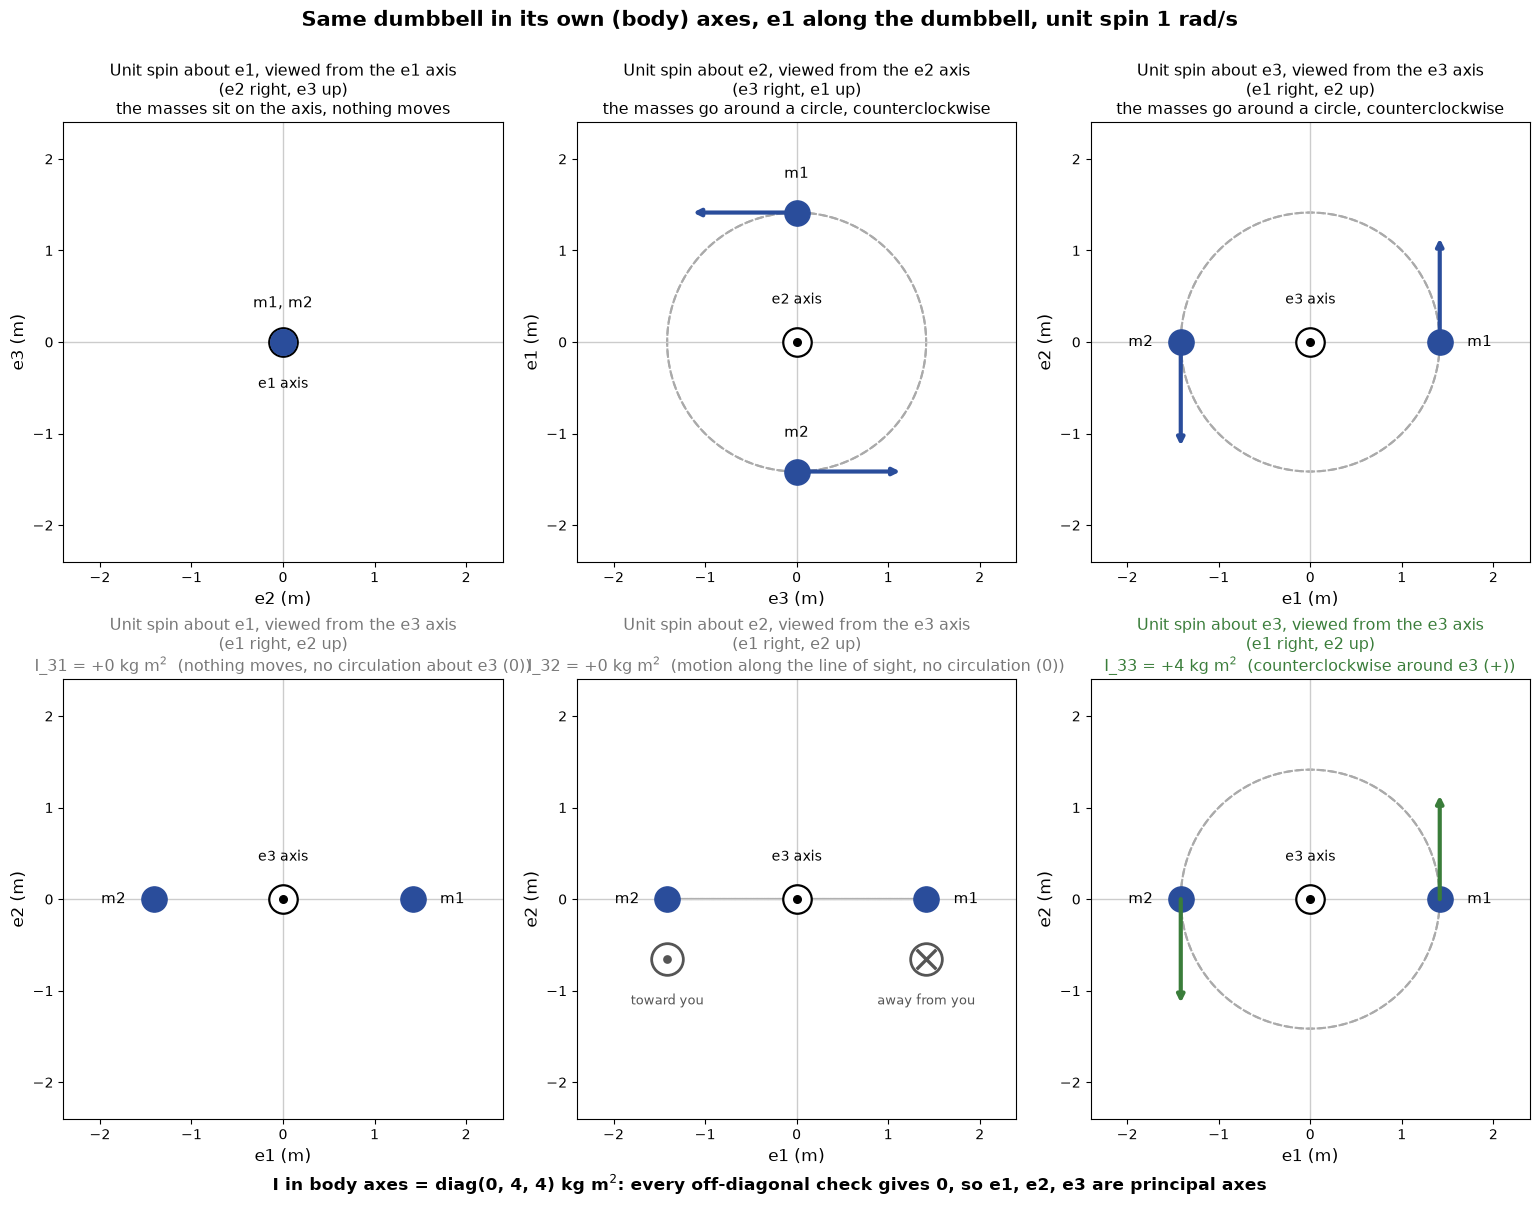

In [5]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------
# STEP 1: the same dumbbell, written in its own (body) axes
#   What we have: two 1 kg masses. In lab axes they sit at (1, 0, 1) m and (-1, 0, -1) m (tilted 45 degrees in the xz plane)
#   What we want: their positions in body axes, where e1 runs along the dumbbell
#   Why: the tilt of the lab picture disappears, the dumbbell is simply along e1
#   half length = sqrt(1^2 + 1^2) = 1.414 m,  r_i = (+-1.414, 0, 0) in (e1, e2, e3)
# ---------------------------------------------------------------
HALF = np.sqrt(2.0)
POS = np.array([[HALF, 0.0, 0.0], [-HALF, 0.0, 0.0]])  # m1, m2 in (e1, e2, e3)
MASS = np.array([1.0, 1.0])  # kg
NAMES = ["m1", "m2"]
AXN = ["e1", "e2", "e3"]
ARROW_SCALE = 0.8  # picture metres per (m/s)

# ---------------------------------------------------------------
# STEP 2: unit spin and the circulation test
#   What we have: unit spin omega = 1 rad/s about one body axis a, velocity v = omega x r
#   What we want: circulation around the viewing axis b, i.e. L_b = sum m (r x v)_b = I_ba * omega
#   Why: net circulation about b (mass weighted) when spinning about a  <=>  I_ba not 0
#   view from axis b: horizontal axis and vertical axis in cyclic order (counterclockwise = positive about b)
# ---------------------------------------------------------------
HV = {0: (1, 2), 1: (2, 0), 2: (0, 1)}  # view axis -> (horizontal index, vertical index)


def spin_vel(a):
    w = np.zeros(3)
    w[a] = 1.0
    return np.cross(w, POS)


def I_entry(b, a):
    v = spin_vel(a)
    return float((MASS[:, None] * np.cross(POS, v))[:, b].sum())


def panel(ax, view, spin, title, color="black", show_circle=False, show_line=False, note=None):
    h, v_ = HV[view]
    vel = spin_vel(spin)
    ax.set_xlim(-2.4, 2.4)
    ax.set_ylim(-2.4, 2.4)
    ax.set_aspect("equal")
    ax.axhline(0, color="#cccccc", lw=1)
    ax.axvline(0, color="#cccccc", lw=1)
    ax.set_xticks([-2, -1, 0, 1, 2])
    ax.set_yticks([-2, -1, 0, 1, 2])
    ax.set_xlabel(f"{AXN[h]} (m)", fontsize=12)
    ax.set_ylabel(f"{AXN[v_]} (m)", fontsize=12)
    ax.set_title(title, fontsize=11.5, color=color)
    if show_circle:
        rad = np.hypot(POS[0, h], POS[0, v_])
    ax.scatter([0], [0], s=420, facecolors="white", edgecolors="black", linewidths=1.6, zorder=3)
    ax.scatter([0], [0], s=30, color="black", zorder=4)
    same_pos = abs(POS[0, h] - POS[1, h]) < 1e-9 and abs(POS[0, v_] - POS[1, v_]) < 1e-9
    ax.text(0, -0.5 if same_pos else 0.42, f"{AXN[view]} axis", ha="center", fontsize=10)
    # true path of each mass seen from this view: project the circle the mass goes around axis 'spin'
    phi = np.linspace(0, 2 * np.pi, 200)
    for k in range(2):
        pts = []
        for f in phi:
            c, s = np.cos(f), np.sin(f)
            if spin == 0:
                R = np.array([[1, 0, 0], [0, c, -s], [0, s, c]])
            elif spin == 1:
                R = np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])
            else:
                R = np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])
            pts.append(R @ POS[k])
        pts = np.array(pts)
        if np.ptp(pts[:, h]) > 1e-9 or np.ptp(pts[:, v_]) > 1e-9:
            ax.plot(pts[:, h], pts[:, v_], color="#aaaaaa", ls="--", lw=1.5, zorder=1)
    for k in range(2):
        ax.scatter(POS[k, h], POS[k, v_], s=330, color="#2a4d9b", zorder=5)
        same = abs(POS[0, h] - POS[1, h]) < 1e-9 and abs(POS[0, v_] - POS[1, v_]) < 1e-9
        if not (same and k == 1):
            lab = f"{NAMES[0]}, {NAMES[1]}" if same else NAMES[k]
            if abs(POS[k, h]) > 1e-9:
                side = 1 if POS[k, h] > 0 else -1
                ax.text(POS[k, h] + side * 0.3, POS[k, v_], lab, ha="left" if side > 0 else "right", va="center", fontsize=11)
            else:
                ax.text(POS[k, h], POS[k, v_] + 0.38, lab, ha="center", fontsize=11)
        vin = np.array([vel[k, h], vel[k, v_]])
        if np.linalg.norm(vin) > 1e-9:
            ax.annotate("", xy=(POS[k, h] + ARROW_SCALE * vin[0], POS[k, v_] + ARROW_SCALE * vin[1]),
                        xytext=(POS[k, h], POS[k, v_]),
                        arrowprops=dict(arrowstyle="-|>", color=color if color != "black" else "#2a4d9b", lw=3,
                                        shrinkA=0, shrinkB=0), zorder=6)
        vout = vel[k, view]
        if abs(vout) > 1e-9:
            mx, my = POS[k, h] + 0.0, POS[k, v_] - 0.65
            ax.scatter(mx, my, s=520, facecolors="white", edgecolors="#555555", linewidths=2.0, zorder=7)
            ax.scatter(mx, my, s=60 if vout > 0 else 200, color="#555555", marker="." if vout > 0 else "x",
                       linewidths=2.4, zorder=8)
            ax.text(mx, my - 0.5, "toward you" if vout > 0 else "away from you", ha="center", fontsize=9.5, color="#555555")
    if note:
        ax.text(0, -2.1, note, ha="center", va="center", fontsize=10)


# ---------------------------------------------------------------
# STEP 3: the 2 x 3 figure, same layout as the lab version
#   top row: unit spin about e1, e2, e3, each viewed along its own axis
#   bottom row: unit spin about e1, e2, e3, all viewed from e3  ->  I_31, I_32, I_33
# ---------------------------------------------------------------
I = np.array([[I_entry(b, a) for a in range(3)] for b in range(3)])
assert np.allclose(I, np.diag([0.0, 4.0, 4.0]))

fig, axes = plt.subplots(2, 3, figsize=(15.5, 12.2))
panel(axes[0, 0], 0, 0, "Unit spin about e1, viewed from the e1 axis\n(e2 right, e3 up)\nthe masses sit on the axis, nothing moves")
panel(axes[0, 1], 1, 1, "Unit spin about e2, viewed from the e2 axis\n(e3 right, e1 up)\nthe masses go around a circle, counterclockwise")
panel(axes[0, 2], 2, 2, "Unit spin about e3, viewed from the e3 axis\n(e1 right, e2 up)\nthe masses go around a circle, counterclockwise")
panel(axes[1, 0], 2, 0, f"Unit spin about e1, viewed from the e3 axis\n(e1 right, e2 up)\n"
      f"I_31 = {I[2, 0]:+.0f} kg m$^2$  (nothing moves, no circulation about e3 (0))", color="#777777")
panel(axes[1, 1], 2, 1, f"Unit spin about e2, viewed from the e3 axis\n(e1 right, e2 up)\n"
      f"I_32 = {I[2, 1]:+.0f} kg m$^2$  (motion along the line of sight, no circulation (0))", color="#777777")
panel(axes[1, 2], 2, 2, f"Unit spin about e3, viewed from the e3 axis\n(e1 right, e2 up)\n"
      f"I_33 = {I[2, 2]:+.0f} kg m$^2$  (counterclockwise around e3 (+))", color="#3a7d3a")
fig.suptitle("Same dumbbell in its own (body) axes, e1 along the dumbbell, unit spin 1 rad/s", fontsize=15, fontweight="bold")
fig.text(0.5, 0.012, "I in body axes = diag(0, 4, 4) kg m$^2$: every off-diagonal check gives 0, so e1, e2, e3 are principal axes",
         ha="center", fontsize=12.5, fontweight="bold")
plt.tight_layout(rect=(0, 0.03, 1, 0.97), h_pad=2.2, w_pad=1.5)
out_path = os.path.join(RESULT_DIR, f"body_view_circulation_check_{TIMESTAMP}.png")
plt.savefig(out_path, dpi=130)
print("saved the figure")
plt.show()